# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ryan Fang, Eloise McDonough, Sufyan Billel

**Date:** 11/2/2026

In [1]:
# Your Phase 1 solution to the problem goes here.

# Q1:

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

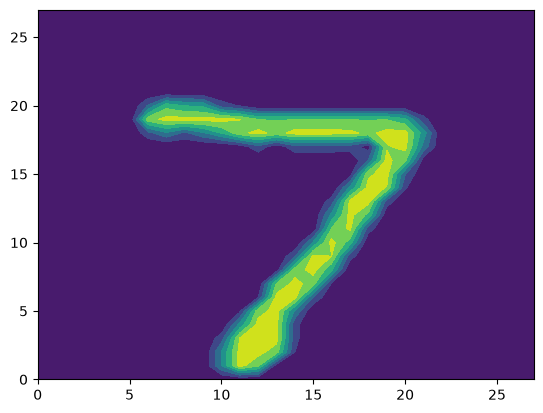

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

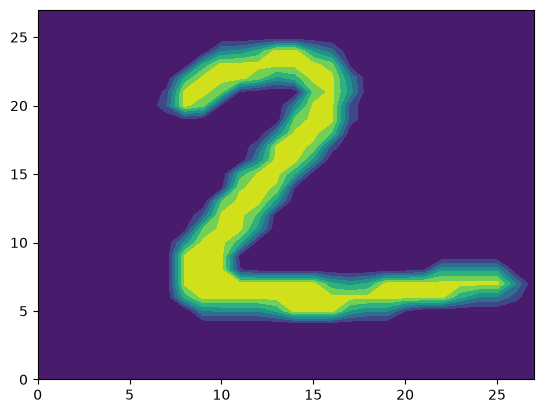

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

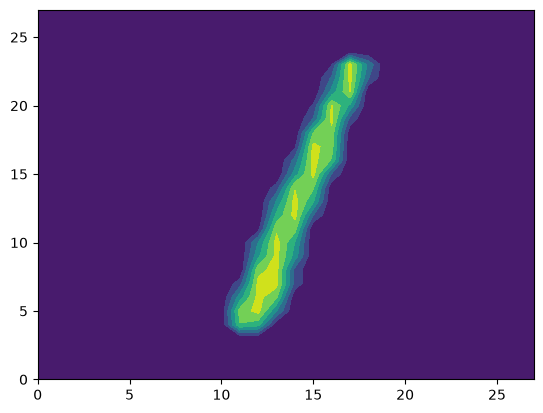

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

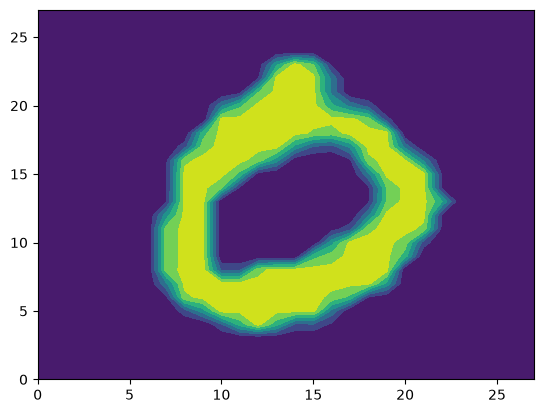

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

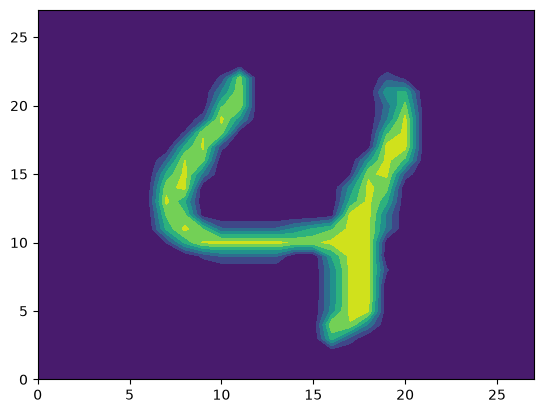

In [2]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# load the data
with open('data/minst.pkl', 'rb') as f:
  data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# visualize the first five numbers in the test set
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
  print(y_test[i], '\n')  # Print the label
  print(X_test[i], '\n')  # Print the matrix of values
  plt.contourf(
      np.rot90(X_test[i].transpose())
  )  # Make a contour plot of the matrix values
  plt.show()

The data are loaded from `data/minst.pkl`, and the first five test observations (`7`, `2`, `1`, `0`, `4`) are printed as $28 \times 28$ pixel intensity matrices (with values from 0 to 255) alongside their corresponding contour plots.

# Q2:

In [3]:
# check the shapes of the training and test sets
print("X_train.shape:", X_train.shape)
print("X_test.shape:", X_test.shape)
print("X_train[i].shape:", X_train[0].shape)
print("X_test[i].shape:", X_test[0].shape)
print("y_train.shape:", y_train.shape)
print("y_test.shape:", y_test.shape)

X_train.shape: (60000, 28, 28)
X_test.shape: (10000, 28, 28)
X_train[i].shape: (28, 28)
X_test[i].shape: (28, 28)
y_train.shape: (60000,)
y_test.shape: (10000,)


* **Shape of `X_train` and `X_test`:** `X_train` has a shape of `(60000, 28, 28)` and `X_test` has a shape of `(10000, 28, 28)`, meaning there are 60,000 training images and 10,000 testing images, each stored as a $28 \times 28$ matrix.
* **Shape of `X_train[i]` and `X_test[i]`:** For each index `i`, both `X_train[i]` and `X_test[i]` have a shape of `(28, 28)`, corresponding to the 28-by-28 grid of pixel values for a single image.
* **Shape of `y_train` and `y_test`:** `y_train` has a shape of `(60000,)` and `y_test` has a shape of `(10000,)`, which are 1D vectors containing the true digit labels (0–9) for each observation.

# Q3:

In [4]:
# convert the 28x28 matrices into 1x784 row vectors using a for loop and .reshape()
Z_train = []
for i in range(len(X_train)):
  Z_train.append(X_train[i].reshape((1, 784)))
Z_train = np.vstack(Z_train)

Z_test = []
for i in range(len(X_test)):
  Z_test.append(X_test[i].reshape((1, 784)))
Z_test = np.vstack(Z_test)

print("Reshaped X_train (Z_train) shape:", Z_train.shape)
print("Reshaped X_test (Z_test) shape:", Z_test.shape)

Reshaped X_train (Z_train) shape: (60000, 784)
Reshaped X_test (Z_test) shape: (10000, 784)


Using a `for` loop and NumPy's `.reshape((1, 784))` method, each $28 \times 28$ image matrix is flattened into a $1 \times 784$ row vector and stacked into a tabular feature matrix. The resulting training matrix `Z_train` has shape `(60000, 784)` and the test matrix `Z_test` has shape `(10000, 784)`.

# Q4:

k = 1: Test Accuracy = 0.9691
k = 3: Test Accuracy = 0.9705
k = 5: Test Accuracy = 0.9688
k = 7: Test Accuracy = 0.9694
k = 9: Test Accuracy = 0.9659
k = 11: Test Accuracy = 0.9668
k = 13: Test Accuracy = 0.9653
k = 15: Test Accuracy = 0.9633

Optimal k: 3 (Accuracy = 0.9705)


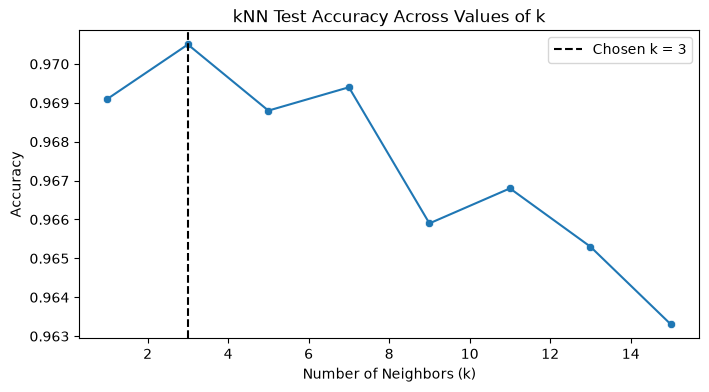

In [5]:
from sklearn.neighbors import KNeighborsClassifier

# test different values of k to find the optimal number of neighbors
k_grid = [1, 3, 5, 7, 9, 11, 13, 15]
accuracies = []

for k in k_grid:
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(Z_train, y_train)
  y_hat = model.predict(Z_test)
  acc = np.mean(y_test == y_hat)
  accuracies.append(acc)
  print(f"k = {k}: Test Accuracy = {acc:.4f}")

k_star = k_grid[np.argmax(accuracies)]
print(f"\nOptimal k: {k_star} (Accuracy = {max(accuracies):.4f})")

# plot accuracy across k values using seaborn
k_df = pd.DataFrame({"k": k_grid, "accuracy": accuracies})
plt.figure(figsize=(8, 4))
sns.lineplot(data=k_df, x="k", y="accuracy")
sns.scatterplot(data=k_df, x="k", y="accuracy")
plt.axvline(k_star, color="black", linestyle="--", label=f"Chosen k = {k_star}")
plt.title("kNN Test Accuracy Across Values of k")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

By fitting `KNeighborsClassifier` across odd values of $k$ from 1 to 15, the optimal number of neighbors is **$k = 3$**, which achieves the highest test accuracy of **0.9705** (97.05%).

# Q5:

In [6]:
# fit the kNN classifier with the optimal k = 3
knn_best = KNeighborsClassifier(n_neighbors=k_star).fit(Z_train, y_train)
y_hat_best = knn_best.predict(Z_test)

# report accuracy
test_accuracy = knn_best.score(Z_test, y_test)
print(f"Optimal k ({k_star}) Test Accuracy: {test_accuracy:.4f}\n")

# compute confusion matrix using pd.crosstab
conf_matrix = pd.crosstab(
    y_test, y_hat_best, rownames=["Actual"], colnames=["Predicted"]
)
print("Confusion Matrix:")
display(conf_matrix)

Optimal k (3) Test Accuracy: 0.9705

Confusion Matrix:


Predicted,0,1,2,3,4,5,6,7,8,9
Actual,,,,,,,,,,
0,974,1,1,0,0,1,2,1,0,0
1,0,1133,2,0,0,0,0,0,0,0
2,10,9,996,2,0,0,0,13,2,0
3,0,2,4,976,1,13,1,7,3,3
4,1,6,0,0,950,0,4,2,0,19
5,6,1,0,11,2,859,5,1,3,4
6,5,3,0,0,3,3,944,0,0,0
7,0,21,5,0,1,0,0,991,0,10
8,8,2,4,16,8,11,3,4,914,4


For the optimal number of neighbors ($k = 3$), the predictor performs very well on the test set, achieving an overall accuracy of **0.9705** (9,705 out of 10,000 test digits classified correctly). 

Looking at the confusion matrix (`pd.crosstab`), the diagonal cells contain the vast majority of observations (ranging from 859 to 1,133 correct predictions per digit), while the off-diagonal cells are very small, showing that the $k$-NN classifier generalizes well across all ten digit classes. Digits with very distinct shapes like `1` (1,133/1,135 correct), `0` (974/980 correct), and `6` (944/958 correct) have the highest accuracy.

# Q6:

In [7]:
# extract off-diagonal entries from the confusion matrix to see the most common mistakes
mistakes = []
for actual in conf_matrix.index:
  for predicted in conf_matrix.columns:
    if actual != predicted:
      mistakes.append({
          'Actual': actual,
          'Predicted': predicted,
          'Count': conf_matrix.loc[actual, predicted],
      })

mistakes_df = pd.DataFrame(mistakes).sort_values(by='Count', ascending=False)
print('Top 10 most frequent classification mistakes:')
display(mistakes_df.head(10))

Top 10 most frequent classification mistakes:


,Actual,Predicted,Count
64,7,1,21
44,4,9,19
75,8,3,16
31,3,5,13
24,2,7,13
48,5,3,11
77,8,5,11
71,7,9,10
18,2,0,10
19,2,1,9


Mistakes w/ our reasoning as to why:
* **Actual `7` predicted as `1` (21 times) and Actual `2` predicted as `7` (13 times) or `1` (9 times):** A `7` written with a short top bar looks similar to a a vertical `1`, and a `2` with a faint bottom stroke looks very similar to a `7` or `1`.
* **Actual `4` predicted as `9` (19 times) and Actual `9` predicted as `4` (9 times):** Handwritten `4`s with a closed or nearly closed top look very similar to `9`s
* **Actual `8` predicted as `3` (16 times) or `5` (11 times), and Actual `3` predicted as `5` (13 times) or Actual `5` predicted as `3` (11 times):** The digits `3`, `5`, and `8` all share curved top and bottom loops, so minor variations where strokes connect can result in small Euclidean distances in pixel space.
* **Actual `7` predicted as `9` (10 times) and Actual `2` predicted as `0` (10 times):** A `7` with a curved upper stroke overlaps with the top loop of a `9`, and a rounded `2` can look similar to some parts of the oval region of a `0`.

The overall pattern is that $k$-NN relies on Euclidean distance across the 784 pixel coordinates, so it seems that mistakes happen between pairs of digits that share overlapping stroke geometry and pixel locations.

# Q7:

To represent a color photo of height $H$ and width $W$ in matrix form, we can use RGB color codes—where every pixel's color is encoded by three numeric values between 0 and 255 representing **Red (R)**, **Green (G)**, and **Blue (B)** intensity. Instead of a single $H \times W$ matrix like in grayscale MNIST, a single color photo is represented as three separate $H \times W$ matrices (one $H \times W$ matrix for Red, one for Green, and one for Blue).

To convert a collection of $N$ color photos into tabular data:
1. For each photo $i$, use `.reshape((1, H * W))` on each of its three $H \times W$ color matrices (Red, Green, and Blue) to flatten them into three row vectors of length $H \times W$.
2. Put those three vectors side-by-side into a single row vector of length $3 \times H \times W$ (for example, a $28 \times 28$ color image becomes a single row vector of $28 \times 28 \times 3 = 2,352$ features: `[R_1, ..., R_784, G_1, ..., G_784, B_1, ..., B_784]`).
3. Stack all $N$ row vectors together so that each row $i$ represents one photo (an observation) and each column $k$ represents a specific pixel-channel value (a feature), producing an $N \times (3 \cdot H \cdot W)$ feature matrix $X$ that can be used directly with standard tabular machine learning models.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [8]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]